In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [74]:
customers = pd.read_csv(
    "../data/raw/customers.csv"
)
customers

,customer_id,name,age,city
0,1,Client_1,56,Bordeaux
1,2,Client_2,69,Paris
2,3,Client_3,46,Paris
3,4,Client_4,32,Paris
4,5,Client_5,60,Paris
...,...,...,...,...
95,96,Client_96,42,Bordeaux
96,97,Client_97,62,Paris
97,98,Client_98,58,Paris
98,99,Client_99,46,Lyon


In [75]:
customers

,customer_id,name,age,city
0,1,Client_1,56,Bordeaux
1,2,Client_2,69,Paris
2,3,Client_3,46,Paris
3,4,Client_4,32,Paris
4,5,Client_5,60,Paris
...,...,...,...,...
95,96,Client_96,42,Bordeaux
96,97,Client_97,62,Paris
97,98,Client_98,58,Paris
98,99,Client_99,46,Lyon


In [76]:
customers.shape


(100, 4)

In [77]:
products = pd.read_csv(
    "../data/raw/products.csv"
)

orders = pd.read_csv(
    "../data/raw/orders.csv"
)

payments = pd.read_csv(
    "../data/raw/payments.csv"
)
products
orders
payments

,order_id,payment_method,payment_status
0,1,PayPal,Paid
1,2,Card,Paid
2,3,PayPal,Paid
3,4,Card,Paid
4,5,Card,Failed
...,...,...,...
495,496,Bank Transfer,Pending
496,497,Card,Paid
497,498,PayPal,Failed
498,499,PayPal,Paid


In [78]:
sales = orders.merge(
    products,
    on="product_id",
    how="left"
)

In [79]:
sales = sales.merge(
    customers,
    on="customer_id",
    how="left"
)
sales.head()


,order_id,customer_id,product_id,quantity,order_date,product_name,category,price,name,age,city
0,1,70,4,2,2025-01-01,Produit_4,Clothing,132,Client_70,19,Paris
1,2,80,8,2,2025-01-02,Produit_8,Electronics,289,Client_80,53,Bordeaux
2,3,93,18,1,2025-01-03,Produit_18,Sports,210,Client_93,64,Lille
3,4,3,5,5,2025-01-04,Produit_5,Home,410,Client_3,46,Paris
4,5,20,9,3,2025-01-05,Produit_9,Electronics,334,Client_20,41,Marseille


In [80]:
sales = sales.merge(
    payments,
    on="order_id",
    how="left"
)

In [81]:
sales["revenue"] = (
    sales["price"]
    *
    sales["quantity"]
)

In [82]:
sales.head()

,order_id,customer_id,product_id,quantity,order_date,product_name,category,price,name,age,city,payment_method,payment_status,revenue
0,1,70,4,2,2025-01-01,Produit_4,Clothing,132,Client_70,19,Paris,PayPal,Paid,264
1,2,80,8,2,2025-01-02,Produit_8,Electronics,289,Client_80,53,Bordeaux,Card,Paid,578
2,3,93,18,1,2025-01-03,Produit_18,Sports,210,Client_93,64,Lille,PayPal,Paid,210
3,4,3,5,5,2025-01-04,Produit_5,Home,410,Client_3,46,Paris,Card,Paid,2050
4,5,20,9,3,2025-01-05,Produit_9,Electronics,334,Client_20,41,Marseille,Card,Failed,1002


In [83]:
sales["revenue"].sum()

393039

In [84]:
revenue_by_category = (
    sales
    .groupby("category")["revenue"]
    .sum()
    .sort_values()
)

In [85]:
customers = pd.read_csv("../data/raw/customers.csv")
products = pd.read_csv("../data/raw/products.csv")
orders = pd.read_csv("../data/raw/orders.csv")
payments = pd.read_csv("../data/raw/payments.csv")

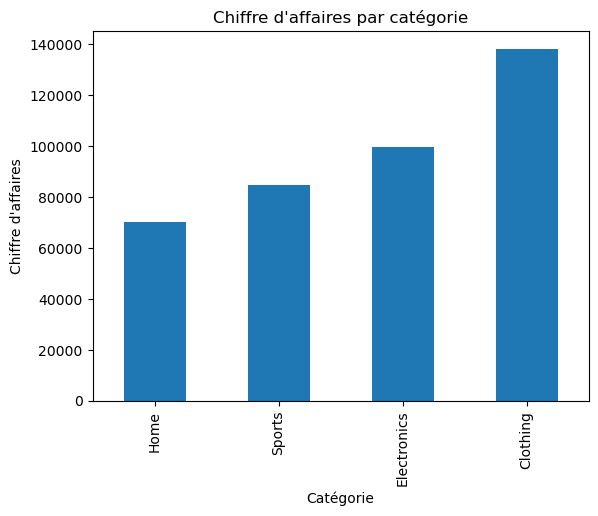

In [86]:
revenue_by_category.plot(
    kind="bar"
)

plt.title(
    "Chiffre d'affaires par catégorie"
)

plt.xlabel(
    "Catégorie"
)

plt.ylabel(
    "Chiffre d'affaires"
)

plt.show()

In [87]:
sales.to_csv(
    "../data/cleaned/sales_cleaned.csv",
    index=False
)

In [88]:
sales["revenue"] = (
    sales["price"]
    *
    sales["quantity"]
)

In [89]:
sales["revenue"].sum()

393039

In [90]:
sales.groupby(
    "category"
)["revenue"].sum()

category
Clothing       138377
Electronics     99587
Home            70143
Sports          84932
Name: revenue, dtype: int64

customers = pd.read_csv("../data/raw/customers.csv")
products = pd.read_csv("../data/raw/products.csv")
orders = pd.read_csv("../data/raw/orders.csv")
payments = pd.read_csv("../data/raw/payments.csv")

In [91]:
customers = pd.read_csv("../data/raw/customers.csv")
products = pd.read_csv("../data/raw/products.csv")
orders = pd.read_csv("../data/raw/orders.csv")
payments = pd.read_csv("../data/raw/payments.csv")

In [92]:
customers.head()


,customer_id,name,age,city
0,1,Client_1,56,Bordeaux
1,2,Client_2,69,Paris
2,3,Client_3,46,Paris
3,4,Client_4,32,Paris
4,5,Client_5,60,Paris


In [93]:
customers.isnull().sum()

customer_id    0
name           0
age            0
city           2
dtype: int64

In [94]:
customers[customers["city"].isnull()]

,customer_id,name,age,city
5,6,Client_6,25,NaN
25,26,Client_26,50,NaN


In [95]:
customers["city"] = customers["city"].fillna("Unknown")

In [96]:
customers.isnull().sum()

customer_id    0
name           0
age            0
city           0
dtype: int64

In [97]:
customers.duplicated().sum()

0

In [98]:
products.duplicated().sum()
orders.duplicated().sum()
payments.duplicated().sum()


0

In [99]:
customers[customers["age"] < 25]

,customer_id,name,age,city
16,17,Client_17,20,Paris
18,19,Client_19,19,Paris
23,24,Client_24,19,Lyon
40,41,Client_41,20,Lyon
43,44,Client_44,24,Bordeaux
48,49,Client_49,21,Bordeaux
54,55,Client_55,19,Lille
58,59,Client_59,24,Bordeaux
68,69,Client_69,21,Paris
69,70,Client_70,19,Paris


In [100]:
customers.groupby("city")["customer_id"].count()

city
Bordeaux     16
Lille        12
Lyon         22
Marseille    19
Paris        29
Unknown       2
Name: customer_id, dtype: int64

In [101]:
customers.groupby("city")["age"].mean().round(2)

city
Bordeaux     43.19
Lille        50.58
Lyon         42.00
Marseille    46.58
Paris        39.76
Unknown      37.50
Name: age, dtype: float64

In [102]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   order_id     500 non-null    int64 
 1   customer_id  500 non-null    int64 
 2   product_id   500 non-null    int64 
 3   quantity     500 non-null    int64 
 4   order_date   500 non-null    object
dtypes: int64(4), object(1)
memory usage: 19.7+ KB


In [103]:
sales = orders.merge(
    products,
    on="product_id",
    how="left"
)

In [104]:
sales.head()

,order_id,customer_id,product_id,quantity,order_date,product_name,category,price
0,1,70,4,2,2025-01-01,Produit_4,Clothing,132
1,2,80,8,2,2025-01-02,Produit_8,Electronics,289
2,3,93,18,1,2025-01-03,Produit_18,Sports,210
3,4,3,5,5,2025-01-04,Produit_5,Home,410
4,5,20,9,3,2025-01-05,Produit_9,Electronics,334


In [105]:
pd.set_option(
    "display.max_columns",
    None
)

In [106]:
sales.head()

,order_id,customer_id,product_id,quantity,order_date,product_name,category,price
0,1,70,4,2,2025-01-01,Produit_4,Clothing,132
1,2,80,8,2,2025-01-02,Produit_8,Electronics,289
2,3,93,18,1,2025-01-03,Produit_18,Sports,210
3,4,3,5,5,2025-01-04,Produit_5,Home,410
4,5,20,9,3,2025-01-05,Produit_9,Electronics,334


In [107]:
orders.to_csv(
    "../data/cleaned/orders_cleaned.csv",
    index=False
)

In [108]:
sales.columns

Index(['order_id', 'customer_id', 'product_id', 'quantity', 'order_date',
       'product_name', 'category', 'price'],
      dtype='object')

In [109]:
sales.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   order_id      500 non-null    int64 
 1   customer_id   500 non-null    int64 
 2   product_id    500 non-null    int64 
 3   quantity      500 non-null    int64 
 4   order_date    500 non-null    object
 5   product_name  500 non-null    object
 6   category      500 non-null    object
 7   price         500 non-null    int64 
dtypes: int64(5), object(3)
memory usage: 31.4+ KB


In [110]:
sales.shape


(500, 8)

In [111]:
sales.head()

,order_id,customer_id,product_id,quantity,order_date,product_name,category,price
0,1,70,4,2,2025-01-01,Produit_4,Clothing,132
1,2,80,8,2,2025-01-02,Produit_8,Electronics,289
2,3,93,18,1,2025-01-03,Produit_18,Sports,210
3,4,3,5,5,2025-01-04,Produit_5,Home,410
4,5,20,9,3,2025-01-05,Produit_9,Electronics,334


In [112]:
import pandas as pd
import numpy as np


# ============================================================
# 1. COPIE DU DATASET
# ============================================================

# On travaille sur une copie pour éviter de modifier accidentellement
# le DataFrame d'origine.
sales = sales.copy()


# ============================================================
# 2. SUPPRESSION DES DOUBLONS
# ============================================================

print("Nombre de doublons avant nettoyage :", sales.duplicated().sum())

sales = sales.drop_duplicates()

print("Nombre de doublons après nettoyage :", sales.duplicated().sum())


# ============================================================
# 3. NETTOYAGE DES NOMS DE COLONNES
# ============================================================

# Supprime les espaces inutiles et met les noms en minuscules.
sales.columns = (
    sales.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("\nColonnes disponibles :")
print(sales.columns.tolist())


# ============================================================
# 4. NETTOYAGE DES COLONNES TEXTE
# ============================================================

text_columns = [
    "name",
    "city",
    "product_name",
    "category",
    "payment_method",
    "payment_status"
]

for column in text_columns:

    if column in sales.columns:

        sales[column] = (
            sales[column]
            .astype("string")
            .str.strip()
        )


# ============================================================
# 5. VALEURS MANQUANTES
# ============================================================

# Ville inconnue
if "city" in sales.columns:

    sales["city"] = (
        sales["city"]
        .fillna("Unknown")
        .replace("", "Unknown")
    )


# Nom client inconnu
if "name" in sales.columns:

    sales["name"] = (
        sales["name"]
        .fillna("Unknown Customer")
        .replace("", "Unknown Customer")
    )


# Produit inconnu
if "product_name" in sales.columns:

    sales["product_name"] = (
        sales["product_name"]
        .fillna("Unknown Product")
        .replace("", "Unknown Product")
    )


# Catégorie inconnue
if "category" in sales.columns:

    sales["category"] = (
        sales["category"]
        .fillna("Unknown")
        .replace("", "Unknown")
    )


# Moyen de paiement inconnu
if "payment_method" in sales.columns:

    sales["payment_method"] = (
        sales["payment_method"]
        .fillna("Unknown")
        .replace("", "Unknown")
    )


# Statut paiement inconnu
if "payment_status" in sales.columns:

    sales["payment_status"] = (
        sales["payment_status"]
        .fillna("Unknown")
        .replace("", "Unknown")
    )


# ============================================================
# 6. CONVERSION DES COLONNES NUMÉRIQUES
# ============================================================

numeric_columns = [
    "customer_id",
    "product_id",
    "order_id",
    "age",
    "quantity",
    "price"
]

for column in numeric_columns:

    if column in sales.columns:

        sales[column] = pd.to_numeric(
            sales[column],
            errors="coerce"
        )


# ============================================================
# 7. NETTOYAGE DES VALEURS NUMÉRIQUES
# ============================================================

# On retire les quantités impossibles
if "quantity" in sales.columns:

    sales.loc[
        sales["quantity"] <= 0,
        "quantity"
    ] = np.nan


# On retire les prix impossibles
if "price" in sales.columns:

    sales.loc[
        sales["price"] < 0,
        "price"
    ] = np.nan


# On retire les âges impossibles
if "age" in sales.columns:

    sales.loc[
        (sales["age"] < 18)
        |
        (sales["age"] > 100),
        "age"
    ] = np.nan


# ============================================================
# 8. GESTION DES VALEURS NUMÉRIQUES MANQUANTES
# ============================================================

# Pour quantity et price :
# on préfère supprimer les lignes problématiques car elles empêchent
# de calculer correctement le chiffre d'affaires.

sales = sales.dropna(
    subset=[
        column
        for column in ["quantity", "price"]
        if column in sales.columns
    ]
)


# Pour l'âge :
# on peut remplacer les valeurs manquantes par l'âge médian.

if "age" in sales.columns:

    median_age = sales["age"].median()

    sales["age"] = sales["age"].fillna(
        median_age
    )


# ============================================================
# 9. CONVERSION DE LA DATE
# ============================================================

if "order_date" in sales.columns:

    sales["order_date"] = pd.to_datetime(
        sales["order_date"],
        errors="coerce"
    )


# Suppression des commandes ayant une date invalide
if "order_date" in sales.columns:

    sales = sales.dropna(
        subset=["order_date"]
    )


# ============================================================
# 10. CRÉATION DU CHIFFRE D'AFFAIRES
# ============================================================

if (
    "quantity" in sales.columns
    and
    "price" in sales.columns
):

    sales["revenue"] = (
        sales["quantity"]
        *
        sales["price"]
    )


# ============================================================
# 11. CRÉATION DES COLONNES DE DATE
# ============================================================

if "order_date" in sales.columns:

    # Année
    sales["year"] = (
        sales["order_date"]
        .dt.year
    )

    # Numéro du mois
    sales["month"] = (
        sales["order_date"]
        .dt.month
    )

    # Nom du mois
    sales["month_name"] = (
        sales["order_date"]
        .dt.month_name()
    )

    # Jour du mois
    sales["day"] = (
        sales["order_date"]
        .dt.day
    )

    # Nom du jour
    sales["day_name"] = (
        sales["order_date"]
        .dt.day_name()
    )

    # Numéro du jour de la semaine
    sales["day_of_week"] = (
        sales["order_date"]
        .dt.dayofweek
    )

    # Année + mois
    sales["year_month"] = (
        sales["order_date"]
        .dt.to_period("M")
        .astype(str)
    )

    # Trimestre
    sales["quarter"] = (
        sales["order_date"]
        .dt.quarter
    )

    # Weekend ou semaine
    sales["is_weekend"] = (
        sales["order_date"]
        .dt.dayofweek
        .isin([5, 6])
    )


# ============================================================
# 12. CRÉATION DES TRANCHES D'ÂGE
# ============================================================

if "age" in sales.columns:

    sales["age_group"] = pd.cut(
        sales["age"],
        bins=[
            17,
            25,
            35,
            45,
            60,
            100
        ],
        labels=[
            "18-25",
            "26-35",
            "36-45",
            "46-60",
            "60+"
        ]
    )


# ============================================================
# 13. CRÉATION D'UNE COLONNE PAYMENT_SUCCESS
# ============================================================

if "payment_status" in sales.columns:

    sales["payment_success"] = (
        sales["payment_status"]
        .str.lower()
        .eq("paid")
    )


# ============================================================
# 14. COLONNE VALEUR MOYENNE / CATÉGORIE DE COMMANDE
# ============================================================

if "revenue" in sales.columns:

    sales["order_value_category"] = pd.cut(
        sales["revenue"],
        bins=[
            -1,
            100,
            500,
            1000,
            float("inf")
        ],
        labels=[
            "Low",
            "Medium",
            "High",
            "Very High"
        ]
    )


# ============================================================
# 15. ARRONDIR LES COLONNES FINANCIÈRES
# ============================================================

if "price" in sales.columns:

    sales["price"] = (
        sales["price"]
        .round(2)
    )


if "revenue" in sales.columns:

    sales["revenue"] = (
        sales["revenue"]
        .round(2)
    )


# ============================================================
# 16. RÉORGANISER L'INDEX
# ============================================================

sales = sales.reset_index(
    drop=True
)


# ============================================================
# 17. VÉRIFICATIONS FINALES
# ============================================================

print("\n==============================")
print("NETTOYAGE TERMINÉ")
print("==============================")

print("\nDimensions finales :")
print(sales.shape)

print("\nValeurs manquantes :")
print(sales.isnull().sum())

print("\nTypes des colonnes :")
print(sales.dtypes)

print("\nPremières lignes :")
display(sales.head())


# ============================================================
# 18. SAUVEGARDE DU DATASET FINAL
# ============================================================

sales.to_csv(
    "../data/cleaned/sales_final.csv",
    index=False
)

print(
    "\nFichier sauvegardé : "
    "../data/cleaned/sales_final.csv"
)

Nombre de doublons avant nettoyage : 0
Nombre de doublons après nettoyage : 0

Colonnes disponibles :
['order_id', 'customer_id', 'product_id', 'quantity', 'order_date', 'product_name', 'category', 'price']

NETTOYAGE TERMINÉ

Dimensions finales :
(500, 19)

Valeurs manquantes :
order_id                0
customer_id             0
product_id              0
quantity                0
order_date              0
product_name            0
category                0
price                   0
revenue                 0
year                    0
month                   0
month_name              0
day                     0
day_name                0
day_of_week             0
year_month              0
quarter                 0
is_weekend              0
order_value_category    0
dtype: int64

Types des colonnes :
order_id                         int64
customer_id                      int64
product_id                       int64
quantity                       float64
order_date              datetime64[

,order_id,customer_id,product_id,quantity,order_date,product_name,category,price,revenue,year,month,month_name,day,day_name,day_of_week,year_month,quarter,is_weekend,order_value_category
0,1,70,4,2.0,2025-01-01,Produit_4,Clothing,132.0,264.0,2025,1,January,1,Wednesday,2,2025-01,1,False,Medium
1,2,80,8,2.0,2025-01-02,Produit_8,Electronics,289.0,578.0,2025,1,January,2,Thursday,3,2025-01,1,False,High
2,3,93,18,1.0,2025-01-03,Produit_18,Sports,210.0,210.0,2025,1,January,3,Friday,4,2025-01,1,False,Medium
3,4,3,5,5.0,2025-01-04,Produit_5,Home,410.0,2050.0,2025,1,January,4,Saturday,5,2025-01,1,True,Very High
4,5,20,9,3.0,2025-01-05,Produit_9,Electronics,334.0,1002.0,2025,1,January,5,Sunday,6,2025-01,1,True,Very High



Fichier sauvegardé : ../data/cleaned/sales_final.csv


In [113]:
sales.columns

Index(['order_id', 'customer_id', 'product_id', 'quantity', 'order_date',
       'product_name', 'category', 'price', 'revenue', 'year', 'month',
       'month_name', 'day', 'day_name', 'day_of_week', 'year_month', 'quarter',
       'is_weekend', 'order_value_category'],
      dtype='object')

In [114]:
# ============================================================
# NETTOYAGE DU TABLEAU CUSTOMERS
# ============================================================

import pandas as pd
import numpy as np

customers = customers.copy()


# 1. Nettoyage des noms de colonnes
customers.columns = (
    customers.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)


# 2. Suppression des doublons
customers = customers.drop_duplicates()


# 3. Conversion de customer_id en nombre
customers["customer_id"] = pd.to_numeric(
    customers["customer_id"],
    errors="coerce"
)


# 4. Suppression des lignes sans customer_id
customers = customers.dropna(
    subset=["customer_id"]
)


# 5. customer_id en entier
customers["customer_id"] = customers["customer_id"].astype(int)


# 6. Nettoyage du nom
customers["name"] = (
    customers["name"]
    .astype("string")
    .str.strip()
)

customers["name"] = (
    customers["name"]
    .fillna("Unknown Customer")
    .replace("", "Unknown Customer")
)


# 7. Nettoyage de la ville
customers["city"] = (
    customers["city"]
    .astype("string")
    .str.strip()
)

customers["city"] = (
    customers["city"]
    .fillna("Unknown")
    .replace("", "Unknown")
)


# 8. Nettoyage de l'âge
customers["age"] = pd.to_numeric(
    customers["age"],
    errors="coerce"
)

# Âges impossibles
customers.loc[
    (customers["age"] < 18)
    |
    (customers["age"] > 100),
    "age"
] = np.nan


# Remplacement des âges manquants par la médiane
customers["age"] = customers["age"].fillna(
    customers["age"].median()
)


# 9. Création des tranches d'âge
customers["age_group"] = pd.cut(
    customers["age"],
    bins=[
        17,
        25,
        35,
        45,
        60,
        100
    ],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-60",
        "60+"
    ]
)


# 10. Reset index
customers = customers.reset_index(
    drop=True
)


# 11. Vérifications
print("===== CUSTOMERS NETTOYÉ =====")
print("\nDimensions :", customers.shape)

print("\nValeurs manquantes :")
print(customers.isnull().sum())

print("\nTypes :")
print(customers.dtypes)

display(customers.head())

===== CUSTOMERS NETTOYÉ =====

Dimensions : (100, 5)

Valeurs manquantes :
customer_id    0
name           0
age            0
city           0
age_group      0
dtype: int64

Types :
customer_id             int32
name           string[python]
age                   float64
city           string[python]
age_group            category
dtype: object


,customer_id,name,age,city,age_group
0,1,Client_1,56.0,Bordeaux,46-60
1,2,Client_2,69.0,Paris,60+
2,3,Client_3,46.0,Paris,46-60
3,4,Client_4,32.0,Paris,26-35
4,5,Client_5,60.0,Paris,46-60


In [115]:
# ============================================================
# NETTOYAGE DU TABLEAU PRODUCTS
# ============================================================

products = products.copy()


# 1. Nettoyage des noms de colonnes
products.columns = (
    products.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)


# 2. Suppression des doublons
products = products.drop_duplicates()


# 3. Nettoyage product_id
products["product_id"] = pd.to_numeric(
    products["product_id"],
    errors="coerce"
)

products = products.dropna(
    subset=["product_id"]
)

products["product_id"] = products[
    "product_id"
].astype(int)


# 4. Nettoyage du nom du produit
products["product_name"] = (
    products["product_name"]
    .astype("string")
    .str.strip()
)

products["product_name"] = (
    products["product_name"]
    .fillna("Unknown Product")
    .replace("", "Unknown Product")
)


# 5. Nettoyage de la catégorie
products["category"] = (
    products["category"]
    .astype("string")
    .str.strip()
)

products["category"] = (
    products["category"]
    .fillna("Unknown")
    .replace("", "Unknown")
)


# 6. Nettoyage du prix
products["price"] = pd.to_numeric(
    products["price"],
    errors="coerce"
)


# Prix négatifs ou nuls considérés comme incorrects
products.loc[
    products["price"] <= 0,
    "price"
] = np.nan


# Suppression des produits sans prix
products = products.dropna(
    subset=["price"]
)


# 7. Arrondir les prix
products["price"] = (
    products["price"]
    .round(2)
)


# 8. Création d'une catégorie de prix
products["price_category"] = pd.cut(
    products["price"],
    bins=[
        0,
        50,
        150,
        300,
        float("inf")
    ],
    labels=[
        "Low",
        "Medium",
        "High",
        "Premium"
    ]
)


# 9. Reset index
products = products.reset_index(
    drop=True
)


# 10. Vérifications
print("===== PRODUCTS NETTOYÉ =====")
print("\nDimensions :", products.shape)

print("\nValeurs manquantes :")
print(products.isnull().sum())

print("\nTypes :")
print(products.dtypes)

display(products.head())

===== PRODUCTS NETTOYÉ =====

Dimensions : (20, 5)

Valeurs manquantes :
product_id        0
product_name      0
category          0
price             0
price_category    0
dtype: int64

Types :
product_id                 int32
product_name      string[python]
category          string[python]
price                    float64
price_category          category
dtype: object


,product_id,product_name,category,price,price_category
0,1,Produit_1,Clothing,448.0,Premium
1,2,Produit_2,Clothing,212.0,High
2,3,Produit_3,Sports,193.0,High
3,4,Produit_4,Clothing,132.0,Medium
4,5,Produit_5,Home,410.0,Premium


In [116]:
# ============================================================
# NETTOYAGE DU TABLEAU PAYMENTS
# ============================================================

payments = payments.copy()


# 1. Nettoyage des noms de colonnes
payments.columns = (
    payments.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)


# 2. Suppression des doublons
payments = payments.drop_duplicates()


# 3. Nettoyage de order_id
payments["order_id"] = pd.to_numeric(
    payments["order_id"],
    errors="coerce"
)


# Suppression des paiements sans order_id
payments = payments.dropna(
    subset=["order_id"]
)


payments["order_id"] = (
    payments["order_id"]
    .astype(int)
)


# 4. Nettoyage payment_method
payments["payment_method"] = (
    payments["payment_method"]
    .astype("string")
    .str.strip()
)


payments["payment_method"] = (
    payments["payment_method"]
    .fillna("Unknown")
    .replace("", "Unknown")
)


# Uniformiser certains noms
payments["payment_method"] = (
    payments["payment_method"]
    .str.title()
)


# 5. Nettoyage payment_status
payments["payment_status"] = (
    payments["payment_status"]
    .astype("string")
    .str.strip()
)


payments["payment_status"] = (
    payments["payment_status"]
    .fillna("Unknown")
    .replace("", "Unknown")
)


payments["payment_status"] = (
    payments["payment_status"]
    .str.title()
)


# 6. Création d'une colonne booléenne
payments["payment_success"] = (
    payments["payment_status"]
    .str.lower()
    .eq("paid")
)


# 7. Création d'une colonne indiquant un échec
payments["payment_failed"] = (
    payments["payment_status"]
    .str.lower()
    .eq("failed")
)


# 8. Reset index
payments = payments.reset_index(
    drop=True
)


# 9. Vérifications
print("===== PAYMENTS NETTOYÉ =====")
print("\nDimensions :", payments.shape)

print("\nValeurs manquantes :")
print(payments.isnull().sum())

print("\nMoyens de paiement :")
print(payments["payment_method"].value_counts())

print("\nStatuts :")
print(payments["payment_status"].value_counts())

display(payments.head())

===== PAYMENTS NETTOYÉ =====

Dimensions : (500, 5)

Valeurs manquantes :
order_id           0
payment_method     0
payment_status     0
payment_success    0
payment_failed     0
dtype: int64

Moyens de paiement :
payment_method
Paypal           174
Card             170
Bank Transfer    156
Name: count, dtype: Int64

Statuts :
payment_status
Paid       431
Pending     40
Failed      29
Name: count, dtype: Int64


,order_id,payment_method,payment_status,payment_success,payment_failed
0,1,Paypal,Paid,True,False
1,2,Card,Paid,True,False
2,3,Paypal,Paid,True,False
3,4,Card,Paid,True,False
4,5,Card,Failed,False,True


In [117]:
# ============================================================
# CRÉATION DU TABLEAU SALES COMPLET
# ============================================================

# 1. Orders + Products
sales = orders.merge(
    products,
    on="product_id",
    how="left"
)


# 2. Ajouter Customers
sales = sales.merge(
    customers,
    on="customer_id",
    how="left"
)


# 3. Ajouter Payments
sales = sales.merge(
    payments,
    on="order_id",
    how="left"
)


# ============================================================
# CRÉATION DU CHIFFRE D'AFFAIRES
# ============================================================

sales["revenue"] = (
    sales["quantity"]
    *
    sales["price"]
)


# ============================================================
# CATÉGORIE DU MONTANT DE LA COMMANDE
# ============================================================

sales["order_value_category"] = pd.cut(
    sales["revenue"],
    bins=[
        -1,
        100,
        500,
        1000,
        float("inf")
    ],
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)


# ============================================================
# ARRONDIR LES VALEURS
# ============================================================

sales["price"] = sales["price"].round(2)

sales["revenue"] = sales["revenue"].round(2)


# ============================================================
# RESET INDEX
# ============================================================

sales = sales.reset_index(
    drop=True
)


# ============================================================
# VÉRIFICATIONS
# ============================================================

print("====================================")
print("TABLEAU SALES FINAL")
print("====================================")

print("\nDimensions :")
print(sales.shape)


print("\nColonnes disponibles :")
print(sales.columns.tolist())


print("\nValeurs manquantes :")
print(sales.isnull().sum())


print("\nPremières lignes :")
display(sales.head())


# ============================================================
# SAUVEGARDE
# ============================================================

sales.to_csv(
    "../data/cleaned/sales_final.csv",
    index=False
)

print(
    "\n✅ sales_final.csv sauvegardé."
)

TABLEAU SALES FINAL

Dimensions :
(500, 19)

Colonnes disponibles :
['order_id', 'customer_id', 'product_id', 'quantity', 'order_date', 'product_name', 'category', 'price', 'price_category', 'name', 'age', 'city', 'age_group', 'payment_method', 'payment_status', 'payment_success', 'payment_failed', 'revenue', 'order_value_category']

Valeurs manquantes :
order_id                0
customer_id             0
product_id              0
quantity                0
order_date              0
product_name            0
category                0
price                   0
price_category          0
name                    0
age                     0
city                    0
age_group               0
payment_method          0
payment_status          0
payment_success         0
payment_failed          0
revenue                 0
order_value_category    0
dtype: int64

Premières lignes :


,order_id,customer_id,product_id,quantity,order_date,product_name,category,price,price_category,name,age,city,age_group,payment_method,payment_status,payment_success,payment_failed,revenue,order_value_category
0,1,70,4,2,2025-01-01,Produit_4,Clothing,132.0,Medium,Client_70,19.0,Paris,18-25,Paypal,Paid,True,False,264.0,Medium
1,2,80,8,2,2025-01-02,Produit_8,Electronics,289.0,High,Client_80,53.0,Bordeaux,46-60,Card,Paid,True,False,578.0,High
2,3,93,18,1,2025-01-03,Produit_18,Sports,210.0,High,Client_93,64.0,Lille,60+,Paypal,Paid,True,False,210.0,Medium
3,4,3,5,5,2025-01-04,Produit_5,Home,410.0,Premium,Client_3,46.0,Paris,46-60,Card,Paid,True,False,2050.0,Very High
4,5,20,9,3,2025-01-05,Produit_9,Electronics,334.0,Premium,Client_20,41.0,Marseille,36-45,Card,Failed,False,True,1002.0,Very High



✅ sales_final.csv sauvegardé.


In [118]:
sales[
    [
        "order_id",
        "customer_id",
        "name",
        "age",
        "city",
        "product_name",
        "category",
        "quantity",
        "price",
        "payment_method",
        "payment_status",
        "revenue"
    ]
].head(10)

,order_id,customer_id,name,age,city,product_name,category,quantity,price,payment_method,payment_status,revenue
0,1,70,Client_70,19.0,Paris,Produit_4,Clothing,2,132.0,Paypal,Paid,264.0
1,2,80,Client_80,53.0,Bordeaux,Produit_8,Electronics,2,289.0,Card,Paid,578.0
2,3,93,Client_93,64.0,Lille,Produit_18,Sports,1,210.0,Paypal,Paid,210.0
3,4,3,Client_3,46.0,Paris,Produit_5,Home,5,410.0,Card,Paid,2050.0
4,5,20,Client_20,41.0,Marseille,Produit_9,Electronics,3,334.0,Card,Failed,1002.0
5,6,59,Client_59,24.0,Bordeaux,Produit_4,Clothing,5,132.0,Card,Paid,660.0
6,7,36,Client_36,32.0,Paris,Produit_17,Clothing,3,106.0,Card,Paid,318.0
7,8,19,Client_19,19.0,Paris,Produit_9,Electronics,4,334.0,Paypal,Paid,1336.0
8,9,90,Client_90,33.0,Lille,Produit_1,Clothing,5,448.0,Card,Paid,2240.0
9,10,67,Client_67,67.0,Marseille,Produit_20,Sports,4,196.0,Card,Paid,784.0


In [119]:
# ============================================================
# NETTOYAGE DU TABLEAU ORDERS
# ============================================================

orders = orders.copy()


# 1. Nettoyage des noms de colonnes
orders.columns = (
    orders.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)


# 2. Suppression des doublons
orders = orders.drop_duplicates()


# 3. Conversion des identifiants
id_columns = [
    "order_id",
    "customer_id",
    "product_id"
]

for column in id_columns:

    orders[column] = pd.to_numeric(
        orders[column],
        errors="coerce"
    )


# 4. Supprimer les lignes sans identifiants importants
orders = orders.dropna(
    subset=[
        "order_id",
        "customer_id",
        "product_id"
    ]
)


# 5. Transformer les IDs en entiers
for column in id_columns:

    orders[column] = (
        orders[column]
        .astype(int)
    )


# 6. Nettoyage de quantity
orders["quantity"] = pd.to_numeric(
    orders["quantity"],
    errors="coerce"
)


# Quantités impossibles
orders.loc[
    orders["quantity"] <= 0,
    "quantity"
] = np.nan


# Suppression des commandes sans quantité valide
orders = orders.dropna(
    subset=["quantity"]
)


# Quantité en entier
orders["quantity"] = (
    orders["quantity"]
    .astype(int)
)


# 7. Conversion de la date
orders["order_date"] = pd.to_datetime(
    orders["order_date"],
    errors="coerce"
)


# Suppression des lignes ayant une date invalide
orders = orders.dropna(
    subset=["order_date"]
)


# 8. Création des colonnes temporelles

orders["year"] = (
    orders["order_date"]
    .dt.year
)

orders["month"] = (
    orders["order_date"]
    .dt.month
)

orders["month_name"] = (
    orders["order_date"]
    .dt.month_name()
)

orders["day"] = (
    orders["order_date"]
    .dt.day
)

orders["day_name"] = (
    orders["order_date"]
    .dt.day_name()
)

orders["day_of_week"] = (
    orders["order_date"]
    .dt.dayofweek
)

orders["quarter"] = (
    orders["order_date"]
    .dt.quarter
)

orders["year_month"] = (
    orders["order_date"]
    .dt.to_period("M")
    .astype(str)
)


# Weekend = samedi ou dimanche
orders["is_weekend"] = (
    orders["order_date"]
    .dt.dayofweek
    .isin([5, 6])
)


# 9. Reset index
orders = orders.reset_index(
    drop=True
)


# 10. Vérifications
print("===== ORDERS NETTOYÉ =====")
print("\nDimensions :", orders.shape)

print("\nValeurs manquantes :")
print(orders.isnull().sum())

print("\nTypes :")
print(orders.dtypes)

display(orders.head())

===== ORDERS NETTOYÉ =====

Dimensions : (500, 14)

Valeurs manquantes :
order_id       0
customer_id    0
product_id     0
quantity       0
order_date     0
year           0
month          0
month_name     0
day            0
day_name       0
day_of_week    0
quarter        0
year_month     0
is_weekend     0
dtype: int64

Types :
order_id                int32
customer_id             int32
product_id              int32
quantity                int32
order_date     datetime64[ns]
year                    int32
month                   int32
month_name             object
day                     int32
day_name               object
day_of_week             int32
quarter                 int32
year_month             object
is_weekend               bool
dtype: object


,order_id,customer_id,product_id,quantity,order_date,year,month,month_name,day,day_name,day_of_week,quarter,year_month,is_weekend
0,1,70,4,2,2025-01-01,2025,1,January,1,Wednesday,2,1,2025-01,False
1,2,80,8,2,2025-01-02,2025,1,January,2,Thursday,3,1,2025-01,False
2,3,93,18,1,2025-01-03,2025,1,January,3,Friday,4,1,2025-01,False
3,4,3,5,5,2025-01-04,2025,1,January,4,Saturday,5,1,2025-01,True
4,5,20,9,3,2025-01-05,2025,1,January,5,Sunday,6,1,2025-01,True


In [120]:
sales["revenue"]

0       264.0
1       578.0
2       210.0
3      2050.0
4      1002.0
        ...  
495     132.0
496     784.0
497    1640.0
498     404.0
499     306.0
Name: revenue, Length: 500, dtype: float64

In [121]:
total_revenue = sales["revenue"].sum()
print(
    f"Chiffre d'affaires total : {total_revenue:.2f} €"
)
total_orders = sales["order_id"].nunique()
print(f"Nombre de commandes total : {total_orders}")
total_customers = sales["customer_id"].nunique()
print(f"Nombre de clients total : {total_customers}")
total_quantity = sales["quantity"].sum()
print(f"Quantité totale vendue : {total_quantity}")
average_basket = (
    total_revenue / total_orders
)
print(
    f"Panier moyen : {average_basket:.2f} €"
)



Chiffre d'affaires total : 393039.00 €
Nombre de commandes total : 500
Nombre de clients total : 98
Quantité totale vendue : 1495
Panier moyen : 786.08 €


Revenu par catégorie :


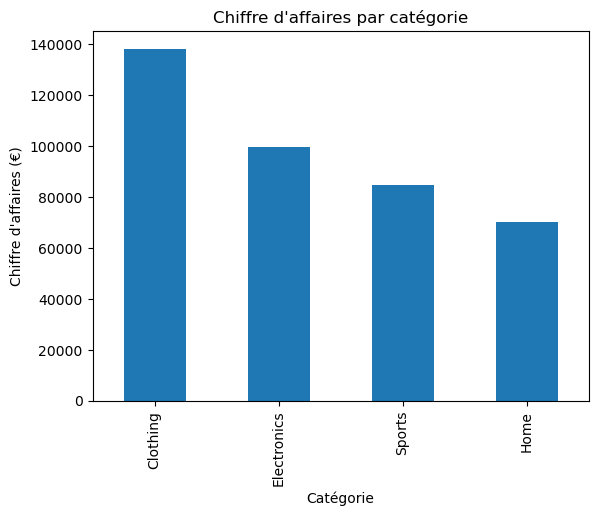

In [122]:
revenue_by_category = (
    sales
    .groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)
print("Revenu par catégorie :")
revenue_by_category
revenue_by_category.plot(
    kind="bar"
)
plt.title(
    "Chiffre d'affaires par catégorie"
)
plt.xlabel(
    "Catégorie"
)
plt.ylabel(
    "Chiffre d'affaires (€)"
)
plt.show()

In [123]:
top_products_quantity = (
    sales
    .groupby("product_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
)


In [124]:
top_10_products = (
    top_products_quantity
    .head(10)
)

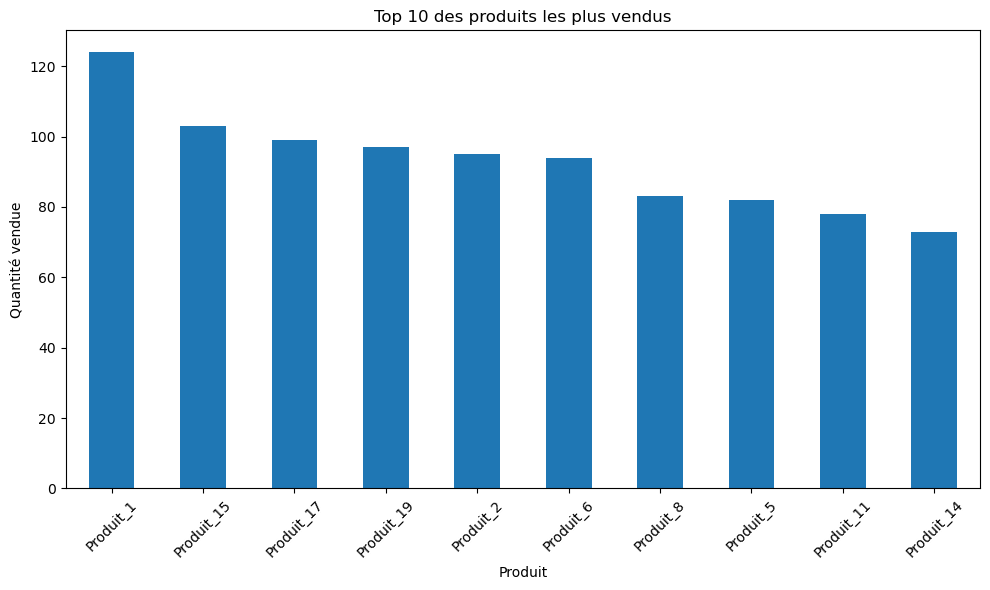

In [125]:
plt.figure(
    figsize=(10, 6)
)

top_10_products.plot(
    kind="bar"
)

plt.title(
    "Top 10 des produits les plus vendus"
)

plt.xlabel(
    "Produit"
)

plt.ylabel(
    "Quantité vendue"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()

Le produit qui génère le plus de CA est Produit_1 avec 55552.00 €.


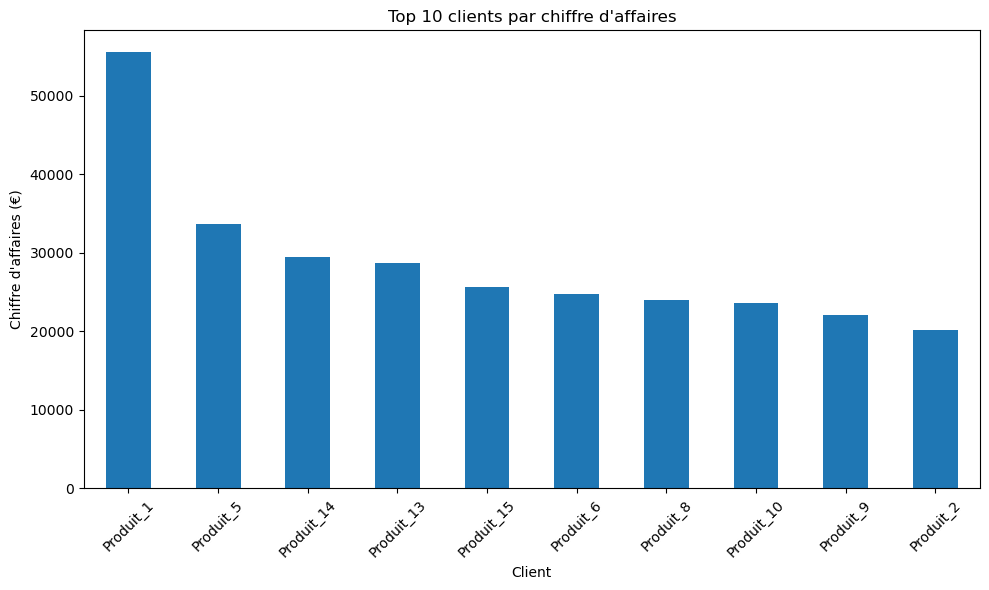

In [126]:
revenue_by_product = (
    sales
    .groupby("product_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
)
revenue_by_product.head(10)
best_product = revenue_by_product.idxmax()
best_product_revenue = revenue_by_product.max()

print(
    f"Le produit qui génère le plus de CA est {best_product} "
    f"avec {best_product_revenue:.2f} €."
)
revenue_by_customer = (
    sales
    .groupby("product_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
)
revenue_by_customer.head(10)
plt.figure(
    figsize=(10, 6)
)

top_10_customers = revenue_by_customer.head(10)
top_10_customers.plot(
    kind="bar"
)

plt.title(
    "Top 10 clients par chiffre d'affaires"
)

plt.xlabel(
    "Client"
)

plt.ylabel(
    "Chiffre d'affaires (€)"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()




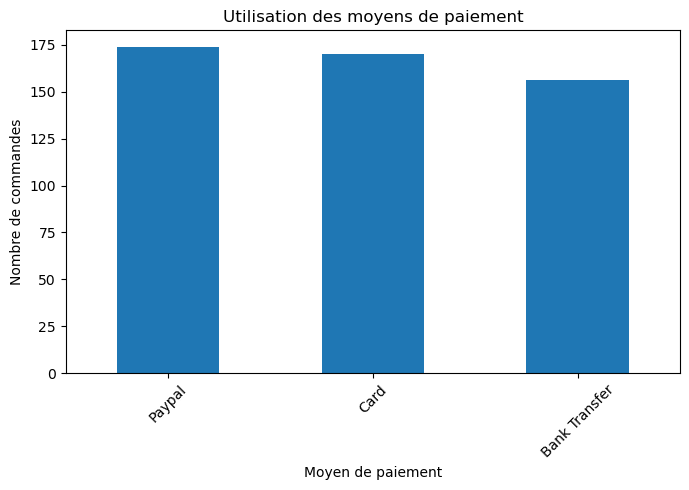

In [127]:
payment_methods = (
    sales["payment_method"]
    .value_counts()
)
plt.figure(
    figsize=(7, 5)
)

payment_methods.plot(
    kind="bar"
)

plt.title(
    "Utilisation des moyens de paiement"
)

plt.xlabel(
    "Moyen de paiement"
)

plt.ylabel(
    "Nombre de commandes"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()


In [129]:
monthly_revenue = (
    sales
    .groupby("year_month")["revenue"]
    .sum()
)

best_month = monthly_revenue.idxmax()
best_month_revenue = monthly_revenue.max()
print(
    f"Meilleur mois : {best_month}"
)
monthly_revenue
plt.figure(
    figsize=(12, 5)
)

monthly_revenue.plot(
    kind="line",
    marker="o"
)

plt.title(
    "Évolution mensuelle du chiffre d'affaires"
)

plt.xlabel(
    "Mois"
)

plt.ylabel(
    "Chiffre d'affaires (€)"
)

plt.grid()

plt.tight_layout()

plt.show()
print(
    f"CA : {best_month_revenue:.2f} €"
)
worst_month = monthly_revenue.idxmin()
worst_month_revenue = monthly_revenue.min()
print(
    f"Pire mois : {worst_month}"
)



KeyError: 'year_month'

In [130]:
sales

,order_id,customer_id,product_id,quantity,order_date,product_name,category,price,price_category,name,age,city,age_group,payment_method,payment_status,payment_success,payment_failed,revenue,order_value_category
0,1,70,4,2,2025-01-01,Produit_4,Clothing,132.0,Medium,Client_70,19.0,Paris,18-25,Paypal,Paid,True,False,264.0,Medium
1,2,80,8,2,2025-01-02,Produit_8,Electronics,289.0,High,Client_80,53.0,Bordeaux,46-60,Card,Paid,True,False,578.0,High
2,3,93,18,1,2025-01-03,Produit_18,Sports,210.0,High,Client_93,64.0,Lille,60+,Paypal,Paid,True,False,210.0,Medium
3,4,3,5,5,2025-01-04,Produit_5,Home,410.0,Premium,Client_3,46.0,Paris,46-60,Card,Paid,True,False,2050.0,Very High
4,5,20,9,3,2025-01-05,Produit_9,Electronics,334.0,Premium,Client_20,41.0,Marseille,36-45,Card,Failed,False,True,1002.0,Very High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,76,4,1,2026-05-11,Produit_4,Clothing,132.0,Medium,Client_76,43.0,Paris,36-45,Bank Transfer,Pending,False,False,132.0,Medium
496,497,24,20,4,2026-05-12,Produit_20,Sports,196.0,High,Client_24,19.0,Lyon,18-25,Card,Paid,True,False,784.0,High
497,498,28,5,4,2026-05-13,Produit_5,Home,410.0,Premium,Client_28,39.0,Paris,36-45,Paypal,Failed,False,True,1640.0,Very High
498,499,8,14,1,2026-05-14,Produit_14,Sports,404.0,Premium,Client_8,56.0,Lyon,46-60,Paypal,Paid,True,False,404.0,Medium


In [132]:
sales["day_name"] = (
    sales["order_date"]
    .dt.day_name()
)
revenue_by_day = (
    sales
    .groupby("day_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
)
revenue_by_day


AttributeError: Can only use .dt accessor with datetimelike values

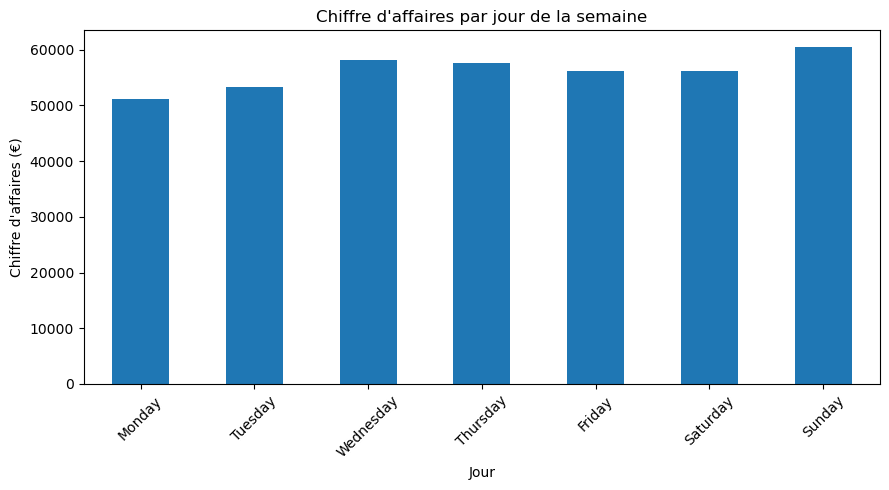

In [ ]:
days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]
revenue_by_day = (
    sales
    .groupby("day_name")["revenue"]
    .sum()
    .reindex(days_order)
)
plt.figure(
    figsize=(9, 5)
)

revenue_by_day.plot(
    kind="bar"
)

plt.title(
    "Chiffre d'affaires par jour de la semaine"
)

plt.xlabel(
    "Jour"
)

plt.ylabel(
    "Chiffre d'affaires (€)"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()



In [ ]:
average_age = (
    sales[
        ["customer_id", "age"]
    ]
    .drop_duplicates(
        subset="customer_id"
    )["age"]
    .mean()
)
print(f"Âge moyen des clients : {average_age:.2f} ans")



Âge moyen des clients : 43.38 ans


In [ ]:
summary = pd.DataFrame({
    "KPI": [
        "Chiffre d'affaires",
        "Commandes",
        "Clients",
        "Quantité vendue",
        "Panier moyen"
    ],

    "Valeur": [
        total_revenue,
        total_orders,
        total_customers,
        total_quantity,
        average_basket
    ]
})
summary 

,KPI,Valeur
0,Chiffre d'affaires,393039.000
1,Commandes,500.000
2,Clients,98.000
3,Quantité vendue,1495.000
4,Panier moyen,786.078


## Conclusions principales

- La catégorie la plus rentable est ...
- La ville générant le plus de CA est ...
- Le produit le plus vendu est ...
- Le meilleur mois est ...
- Le moyen de paiement le plus utilisé est ...
- Le taux de paiement réussi est ... %

In [ ]:
sales.to_csv(
    "../data/cleaned/sales_final.csv",
    index=False
)

NameError: name 'sales' is not defined